# 03 · ผล TEST แบบละเอียด · expert01 + expert02
ใช้รุ่น final ที่ fit TRAIN+VAL แล้วทดสอบกับคลิป TEST ที่กันไว้ หลังล็อกตัวเลือก
เล่มนี้ประเมินอย่างเดียว ไม่ fit หรือเปลี่ยนพารามิเตอร์ และไม่เปลี่ยนโมเดลเว็บ

แยก **usable** (landmark/feature ครบ) กับ **all reviewed** (รวมเฟรมที่ตรวจ landmark ไม่ได้)
เฟรมที่ตรวจไม่ได้มีผล `__unavailable__` และนับเป็นทายไม่สำเร็จ ไม่เติมว่าท่าถูก
คะแนนหลัก **clip-balanced Macro F1** ให้น้ำหนักรวมแต่ละคลิปเท่ากัน และเฉลี่ยทุกคลาสเท่ากัน

## 1.1 · โหลดเครื่องมือ

In [1]:
from pathlib import Path
import sys, json
PROJECT = next(p for p in [Path.cwd(), *Path.cwd().parents]
               if (p/'training/src/training/combined_experts.py').exists())
if str(PROJECT/'training') not in sys.path:
    sys.path.insert(0, str(PROJECT/'training'))
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image
from src.training import combined_experts as ce
ce.setup_plots()
pd.set_option('display.max_columns', 25)
pd.set_option('display.max_colwidth', 100)
print('Python:', sys.executable)
print('Training directory:', ce.ROOT)
print('scikit-learn:', ce.sklearn.__version__)
WEB_BEFORE = ce.web_fingerprints()


Python: E:\Kamsuay\SawUAI\training\.venv\Scripts\python.exe
Training directory: E:\Kamsuay\SawUAI\training
scikit-learn: 1.9.1


## 1.2 · ระบุ run และยืนยันตัวเลือกที่ล็อกไว้

In [2]:
RUN = 'combined_experts_20261007_211339_512861'
REPORT = ce.ROOT/'reports'/RUN
MODEL_DIR = ce.ROOT/'models'/RUN
SPLIT = 'test'
MODEL_FOLDER = 'final'
record = ce.read_json(REPORT/'training_record.json')
lock = ce.read_json(REPORT/'selection_lock.json')
assert lock['selection_sha256'] == ce.sha256(REPORT/'selection.json')
assert lock['test_used_for_selection'] is False
for task in ce.TASKS:
    expected = record['tasks'][task]['final_model_sha256']
    assert ce.sha256(MODEL_DIR/MODEL_FOLDER/f'{task}.joblib') == expected
print('Run:',RUN)
print('Fit splits:', ["train","val"])
print('Evaluation split:',SPLIT)

Run: combined_experts_20261007_211339_512861
Fit splits: ['train', 'val']
Evaluation split: test


## 2.1 · จำนวนภาพที่ตรวจได้และตรวจไม่ได้
จำนวนแต่ละงานอาจซ้อนกันเพราะใช้ภาพเดียวกัน อย่ารวมเป็นจำนวนภาพต้นฉบับ
Coverage คือจำนวนที่ feature ครบ / จำนวนเฟรมที่ผู้ตรวจเลือกสำหรับงานนั้น

In [3]:
inventory = []
for dataset in sorted({s['dataset'] for s in ce.TASKS.values()}):
    usable = pd.read_csv(ce.DATA/dataset/f'{SPLIT}.csv')
    audit = pd.read_csv(ce.DATA/dataset/f'{SPLIT}_audit.csv')
    inventory.append(dict(dataset=dataset,reviewed_frames=len(audit),usable_frames=len(usable),
        excluded_frames=len(audit)-len(usable),clips=audit.clip_id.nunique(),coverage=len(usable)/len(audit)))
display(pd.DataFrame(inventory).round(4))

,dataset,reviewed_frames,usable_frames,excluded_frames,clips,coverage
0,bow_angle_float_body_proxy,116,77,39,11,0.6638
1,initial_grip_rightmost,70,53,17,10,0.7571
2,playing_posture_head_shoulder,268,268,0,7,1.0000


## 2.2 · ความหมายคะแนน
- **Accuracy:** สัดส่วนที่ทายถูก
- **Precision:** เมื่อแจ้งว่าผิด มีคำตอบจริงผิดกี่ส่วน
- **Recall:** จากภาพที่ผิดจริง ตรวจพบกี่ส่วน
- **F1:** รวม Precision และ Recall; Macro F1 เฉลี่ยทุกคลาสเท่ากัน
- **Clip-balanced:** น้ำหนักรวมต่อคลิปเท่ากัน ลดผลจากคลิปที่มีเฟรมมาก
- **Support:** จำนวนเฟรมในตารางปกติ; ในตารางถ่วงน้ำหนักคือผลรวมน้ำหนัก ไม่ใช่จำนวนเฟรม
Model support จาก predict_proba ยังไม่ใช่เปอร์เซ็นต์ความแม่นยำที่ปรับเทียบแล้ว

## 3.1 · ทำนายและบันทึกผลทุกงาน

In [4]:
results, rows_by_task, bundles = {}, {}, {}
for task in ce.TASKS:
    bundle = joblib.load(MODEL_DIR/MODEL_FOLDER/f'{task}.joblib')
    expected_fit = ['train','val'] if SPLIT=='test' else ['train']
    assert bundle['fit_splits'] == expected_fit
    result,rows = ce.evaluate_bundle(task,bundle,SPLIT,REPORT)
    results[task],rows_by_task[task],bundles[task] = result,rows,bundle
scores = ce.result_table(results)
display(scores.round(4))
scores.to_csv(REPORT/SPLIT/'summary_scores.csv',index=False,encoding='utf-8-sig')
ce.save_json(REPORT/SPLIT/'results.json',results)

,task,family,features,usable_frames,reviewed_frames,clips,usable_accuracy,usable_macro_f1,balanced_f1_usable,balanced_accuracy_all,balanced_f1_all,balanced_coverage
0,ก้มหน้า,random_forest,10,268,268,7,0.8470,0.7134,0.6782,0.7925,0.6782,1.0000
1,ไหล่เอียง,random_forest,10,268,268,7,0.8396,0.7931,0.7830,0.7992,0.7830,1.0000
2,จับคันชักตอนเริ่ม,random_forest,2,53,70,10,0.8679,0.8590,0.8645,0.6834,0.8043,0.7893
3,ควรปรับองศาการสี,decision_tree,4,77,116,11,0.8312,0.7688,0.7541,0.6824,0.6309,0.7284


## 3.2 · เปรียบเทียบคะแนน usable กับคะแนนรวมทั้งหมด
คะแนน usable บอกความสามารถตัวจำแนกเมื่อได้รับ feature ครบ
คะแนน all reviewed รวมปัญหา landmark ของ pipeline ด้วย จึงอาจต่ำกว่า
ตารางหลักไม่ซ่อนเฟรมที่โมเดลทายผิดหรือ landmark ไม่ครบ

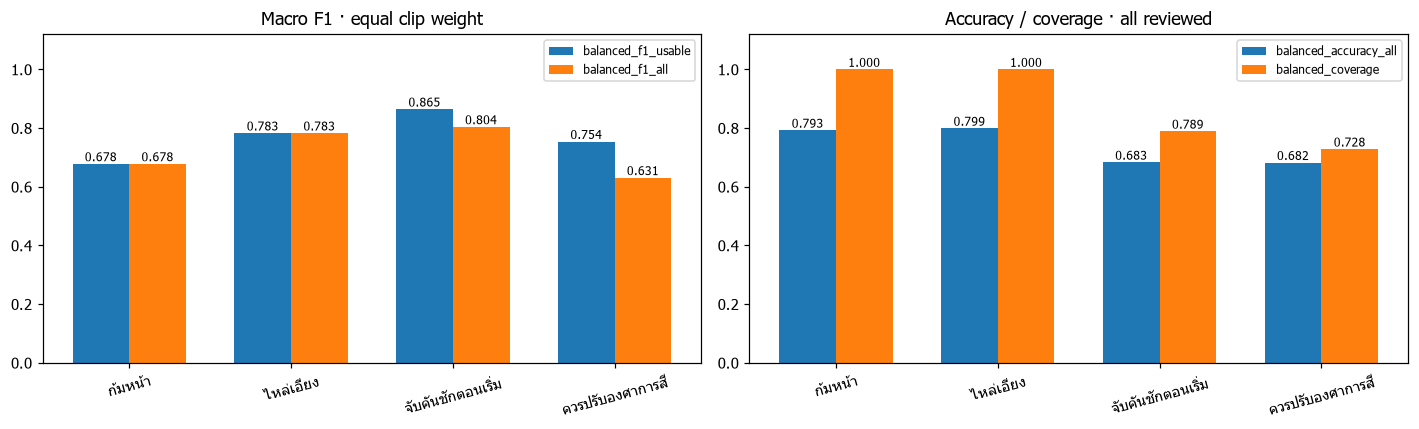

In [5]:
fig,axes = plt.subplots(1,2,figsize=(13,4))
x = np.arange(len(scores)); width=.35
for ax,cols,title in [
    (axes[0],['balanced_f1_usable','balanced_f1_all'],'Macro F1 · equal clip weight'),
    (axes[1],['balanced_accuracy_all','balanced_coverage'],'Accuracy / coverage · all reviewed')]:
    for offset,col in enumerate(cols):
        bars=ax.bar(x+(offset-.5)*width,scores[col],width,label=col)
        ax.bar_label(bars,fmt='%.3f',fontsize=8)
    ax.set_xticks(x,scores.task,rotation=15); ax.set(ylim=(0,1.12),title=title); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(REPORT/SPLIT/'scores.png'); plt.show()

## 4.1 · เทียบกับ Dummy ที่เรียนจาก TRAIN+VAL
Dummy เป็นฐานตรวจว่าผลเหนือการตอบคลาสส่วนใหญ่หรือไม่ โดยไม่ได้ใช้ TEST fit
ไม่ใช้คะแนนตารางนี้เลือกโมเดลใหม่

In [6]:
baseline_rows=[]
for task,spec in ce.TASKS.items():
    fit_df=pd.concat([ce.load_split(task,'train'),ce.load_split(task,'val')],ignore_index=True)
    test_df=ce.load_split(task,'test')
    dummy=ce.DummyClassifier(strategy='most_frequent').fit(
        fit_df[bundles[task]['feature_columns']],fit_df[spec['target']],sample_weight=ce.clip_weights(fit_df))
    m=ce.metric_values(test_df,spec['target'],dummy.predict(test_df[bundles[task]['feature_columns']]),spec['labels'])
    baseline_rows.append(dict(task=spec['title'],selected_f1=results[task]['conditional']['clip_balanced_macro_f1'],
                              dummy_f1=m['clip_balanced_macro_f1']))
display(pd.DataFrame(baseline_rows).round(4))

,task,selected_f1,dummy_f1
0,ก้มหน้า,0.6782,0.4626
1,ไหล่เอียง,0.7830,0.4167
2,จับคันชักตอนเริ่ม,0.8645,0.2500
3,ควรปรับองศาการสี,0.7541,0.4678


## 5 · รายละเอียดงาน ก้มหน้า
ตารางแรกเป็นจำนวนเฟรมจริง ส่วนตารางที่สองถ่วงน้ำหนักคลิปเท่ากัน
Confusion matrix มีคอลัมน์ “จุดไม่ครบ” เพื่อเห็นภาพที่ pipeline ประเมินไม่ได้
แถวเป็นคำตอบจริง คอลัมน์เป็นผลทำนาย

,precision,recall,f1-score,support
0,0.9579,0.8650,0.9091,237.000
1,0.4074,0.7097,0.5176,31.000
accuracy,0.8470,0.8470,0.8470,0.847
macro avg,0.6827,0.7873,0.7134,268.000
weighted avg,0.8943,0.8470,0.8638,268.000


,precision,recall,f1-score,support
0,0.9442,0.8066,0.8700,6.0255
1,0.3711,0.7055,0.4863,0.9745
accuracy,0.7925,0.7925,0.7925,0.7925
macro avg,0.6577,0.7560,0.6782,7.0000
weighted avg,0.8644,0.7925,0.8166,7.0000


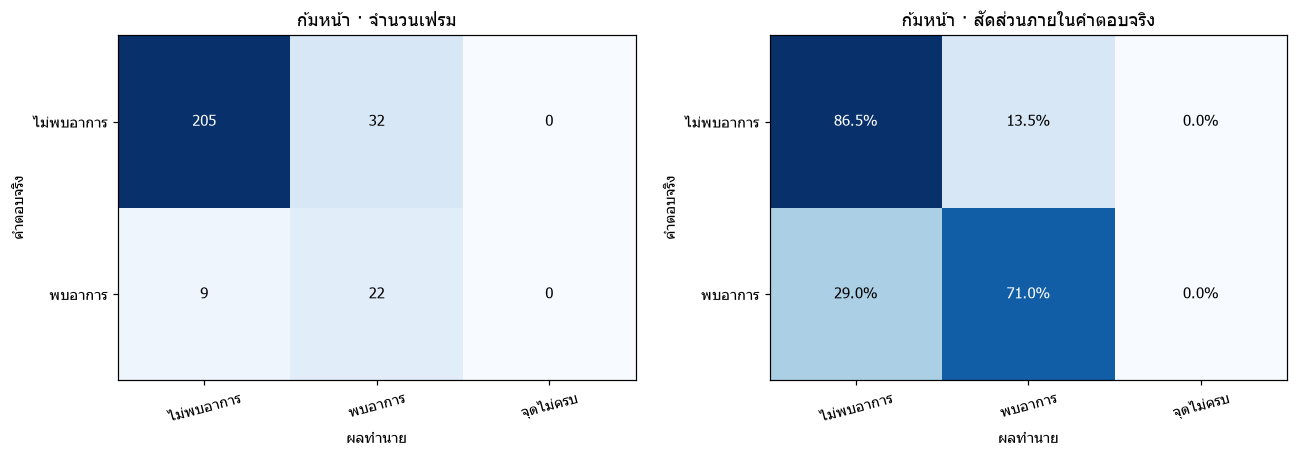

In [7]:
task = 'head_down'
metric = results[task]
display(pd.DataFrame(metric['classification_reports']['unweighted']).T.round(4))
display(pd.DataFrame(metric['classification_reports']['clip_balanced']).T.round(4))
fig=ce.plot_confusions(task,rows_by_task[task])
fig.savefig(REPORT/SPLIT/f'confusion_{task}.png'); plt.show()

### 5 · ก้มหน้า: ผลรายคนและรายคลิป

,frames,clips,frame_accuracy,frame_macro_f1,clip_balanced_accuracy,clip_balanced_macro_f1,coverage,clip_balanced_coverage
expert_01,184.0,4.0,0.9239,0.8567,0.8869,0.8396,1.0,1.0
expert_02,84.0,3.0,0.6786,0.4043,0.6667,0.4000,1.0,1.0


,expert,true_class_counts,missing_classes,macro_f1_observed_classes
0,expert_01,"{'0': 154, '1': 30}",[],0.8396
1,expert_02,"{'0': 83, '1': 1}",[],0.4000


The chart uses fixed classes. Missing classes can lower Macro F1 even without errors; read class counts and accuracy together.


,clip_id,expert,frames,available,accuracy,positive_frames
5,expert_02/playing_posture/E02_PP_head_down_S01_T04.mp4.mp4,expert_02,27,27,0.0000,1
2,expert_01/playing_posture/E01_PP_head_down_S01_T03.mp4.mp4,expert_01,32,32,0.7500,30
0,expert_01/playing_posture/E01_PP_back_hunched_S01_T05.mp4.mp4,expert_01,26,26,0.8077,0
1,expert_01/playing_posture/E01_PP_correct_S01_T02.mp4.mp4,expert_01,101,101,0.9901,0
3,expert_01/playing_posture/E01_PP_shoulder_tilt_S01_T01.mp4.mp4,expert_01,25,25,1.0000,0
4,expert_02/playing_posture/E02_PP_correct_S01_T04.mp4.mp4,expert_02,29,29,1.0000,0
6,expert_02/playing_posture/E02_PP_shoulder_tilt_S01_T05.mp4.mp4,expert_02,28,28,1.0000,0


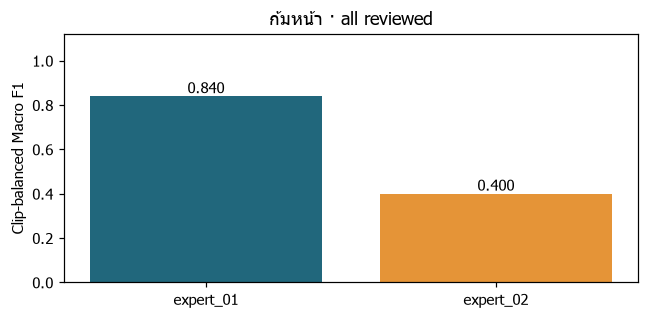

In [8]:
task = 'head_down'
expert_table=pd.DataFrame(results[task]['per_expert']).T
display(expert_table.round(4))
# A class can be absent for one player even when present in the full split.
expert_classes=[]
for expert,g in rows_by_task[task].groupby('expert'):
    observed=[label for label in ce.TASKS[task]['labels'] if (g.truth==label).any()]
    expert_classes.append(dict(expert=expert,
        true_class_counts=g.truth.value_counts().to_dict(),
        missing_classes=[label for label in ce.TASKS[task]['labels'] if label not in observed],
        macro_f1_observed_classes=ce.f1_score(g.truth,g.prediction,labels=observed,
            average='macro',sample_weight=ce.clip_weights(g),zero_division=0)))
display(pd.DataFrame(expert_classes).round(4))
print('The chart uses fixed classes. Missing classes can lower Macro F1 even without errors; read class counts and accuracy together.')
per_clip=pd.read_csv(REPORT/SPLIT/'selected'/f'{task}_per_clip.csv')
display(per_clip.sort_values('accuracy').head(12).round(4))
fig,ax=plt.subplots(figsize=(6,3))
bars=ax.bar(expert_table.index,expert_table.clip_balanced_macro_f1,color=['#21677c','#e59437'])
ax.bar_label(bars,fmt='%.3f'); ax.set(ylim=(0,1.12),title='ก้มหน้า · all reviewed',ylabel='Clip-balanced Macro F1')
fig.tight_layout(); fig.savefig(REPORT/SPLIT/f'expert_{task}.png'); plt.show()

## 5 · รายละเอียดงาน ไหล่เอียง
ตารางแรกเป็นจำนวนเฟรมจริง ส่วนตารางที่สองถ่วงน้ำหนักคลิปเท่ากัน
Confusion matrix มีคอลัมน์ “จุดไม่ครบ” เพื่อเห็นภาพที่ pipeline ประเมินไม่ได้
แถวเป็นคำตอบจริง คอลัมน์เป็นผลทำนาย

,precision,recall,f1-score,support
0,0.9778,0.8186,0.8911,215.0000
1,0.5568,0.9245,0.6950,53.0000
accuracy,0.8396,0.8396,0.8396,0.8396
macro avg,0.7673,0.8716,0.7931,268.0000
weighted avg,0.8945,0.8396,0.8524,268.0000


,precision,recall,f1-score,support
0,0.9591,0.7509,0.8424,5.0000
1,0.5964,0.9200,0.7236,2.0000
accuracy,0.7992,0.7992,0.7992,0.7992
macro avg,0.7777,0.8355,0.7830,7.0000
weighted avg,0.8555,0.7992,0.8084,7.0000


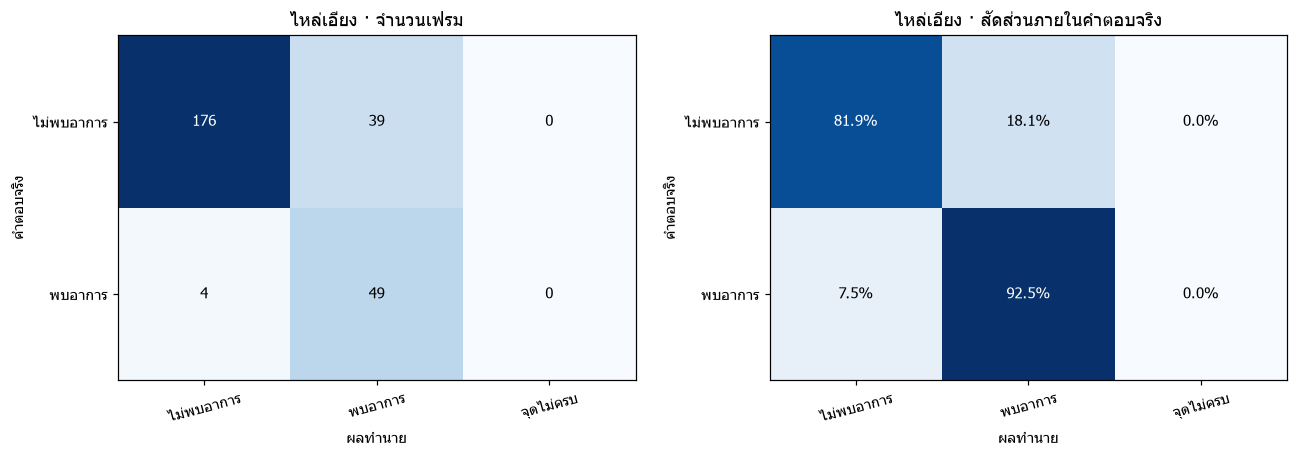

In [9]:
task = 'shoulder_tilt'
metric = results[task]
display(pd.DataFrame(metric['classification_reports']['unweighted']).T.round(4))
display(pd.DataFrame(metric['classification_reports']['clip_balanced']).T.round(4))
fig=ce.plot_confusions(task,rows_by_task[task])
fig.savefig(REPORT/SPLIT/f'confusion_{task}.png'); plt.show()

### 5 · ไหล่เอียง: ผลรายคนและรายคลิป

,frames,clips,frame_accuracy,frame_macro_f1,clip_balanced_accuracy,clip_balanced_macro_f1,coverage,clip_balanced_coverage
expert_01,184.0,4.0,0.7989,0.7018,0.7004,0.6748,1.0,1.0
expert_02,84.0,3.0,0.9286,0.9233,0.9310,0.9259,1.0,1.0


,expert,true_class_counts,missing_classes,macro_f1_observed_classes
0,expert_01,"{'0': 159, '1': 25}",[],0.6748
1,expert_02,"{'0': 56, '1': 28}",[],0.9259


The chart uses fixed classes. Missing classes can lower Macro F1 even without errors; read class counts and accuracy together.


,clip_id,expert,frames,available,accuracy,positive_frames
2,expert_01/playing_posture/E01_PP_head_down_S01_T03.mp4.mp4,expert_01,32,32,0.0000,0
4,expert_02/playing_posture/E02_PP_correct_S01_T04.mp4.mp4,expert_02,29,29,0.7931,0
3,expert_01/playing_posture/E01_PP_shoulder_tilt_S01_T01.mp4.mp4,expert_01,25,25,0.8400,25
0,expert_01/playing_posture/E01_PP_back_hunched_S01_T05.mp4.mp4,expert_01,26,26,0.9615,0
1,expert_01/playing_posture/E01_PP_correct_S01_T02.mp4.mp4,expert_01,101,101,1.0000,0
5,expert_02/playing_posture/E02_PP_head_down_S01_T04.mp4.mp4,expert_02,27,27,1.0000,0
6,expert_02/playing_posture/E02_PP_shoulder_tilt_S01_T05.mp4.mp4,expert_02,28,28,1.0000,28


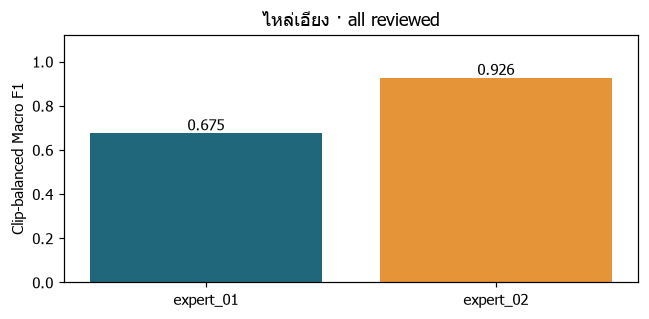

In [10]:
task = 'shoulder_tilt'
expert_table=pd.DataFrame(results[task]['per_expert']).T
display(expert_table.round(4))
# A class can be absent for one player even when present in the full split.
expert_classes=[]
for expert,g in rows_by_task[task].groupby('expert'):
    observed=[label for label in ce.TASKS[task]['labels'] if (g.truth==label).any()]
    expert_classes.append(dict(expert=expert,
        true_class_counts=g.truth.value_counts().to_dict(),
        missing_classes=[label for label in ce.TASKS[task]['labels'] if label not in observed],
        macro_f1_observed_classes=ce.f1_score(g.truth,g.prediction,labels=observed,
            average='macro',sample_weight=ce.clip_weights(g),zero_division=0)))
display(pd.DataFrame(expert_classes).round(4))
print('The chart uses fixed classes. Missing classes can lower Macro F1 even without errors; read class counts and accuracy together.')
per_clip=pd.read_csv(REPORT/SPLIT/'selected'/f'{task}_per_clip.csv')
display(per_clip.sort_values('accuracy').head(12).round(4))
fig,ax=plt.subplots(figsize=(6,3))
bars=ax.bar(expert_table.index,expert_table.clip_balanced_macro_f1,color=['#21677c','#e59437'])
ax.bar_label(bars,fmt='%.3f'); ax.set(ylim=(0,1.12),title='ไหล่เอียง · all reviewed',ylabel='Clip-balanced Macro F1')
fig.tight_layout(); fig.savefig(REPORT/SPLIT/f'expert_{task}.png'); plt.show()

## 5 · รายละเอียดงาน จับคันชักตอนเริ่ม
ตารางแรกเป็นจำนวนเฟรมจริง ส่วนตารางที่สองถ่วงน้ำหนักคลิปเท่ากัน
Confusion matrix มีคอลัมน์ “จุดไม่ครบ” เพื่อเห็นภาพที่ pipeline ประเมินไม่ได้
แถวเป็นคำตอบจริง คอลัมน์เป็นผลทำนาย

,precision,recall,f1-score,support
none,0.8438,0.5870,0.6923,46.0
grip_too_high,0.8182,0.7500,0.7826,12.0
grip_too_low,1.0000,0.8333,0.9091,12.0
micro avg,0.8679,0.6571,0.7480,70.0
macro avg,0.8873,0.7234,0.7947,70.0
weighted avg,0.8662,0.6571,0.7450,70.0


,precision,recall,f1-score,support
none,0.8148,0.6113,0.6985,6.0
grip_too_high,0.8693,0.7500,0.8053,2.0
grip_too_low,1.0000,0.8333,0.9091,2.0
micro avg,0.8659,0.6834,0.7639,10.0
macro avg,0.8947,0.7315,0.8043,10.0
weighted avg,0.8628,0.6834,0.7620,10.0


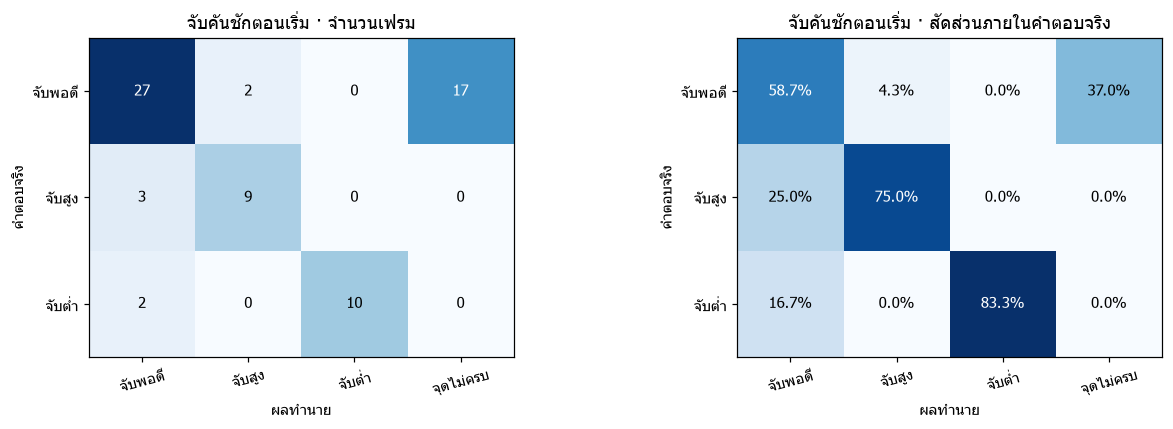

In [11]:
task = 'initial_grip'
metric = results[task]
display(pd.DataFrame(metric['classification_reports']['unweighted']).T.round(4))
display(pd.DataFrame(metric['classification_reports']['clip_balanced']).T.round(4))
fig=ce.plot_confusions(task,rows_by_task[task])
fig.savefig(REPORT/SPLIT/f'confusion_{task}.png'); plt.show()

### 5 · จับคันชักตอนเริ่ม: ผลรายคนและรายคลิป

,frames,clips,frame_accuracy,frame_macro_f1,clip_balanced_accuracy,clip_balanced_macro_f1,coverage,clip_balanced_coverage
expert_01,42.0,5.0,0.6190,0.7600,0.6535,0.7709,0.7143,0.7653
expert_02,28.0,5.0,0.7143,0.8125,0.7133,0.8164,0.8214,0.8133


,expert,true_class_counts,missing_classes,macro_f1_observed_classes
0,expert_01,"{'none': 30, 'grip_too_high': 6, 'grip_too_low': 6}",[],0.7709
1,expert_02,"{'none': 16, 'grip_too_high': 6, 'grip_too_low': 6}",[],0.8164


The chart uses fixed classes. Missing classes can lower Macro F1 even without errors; read class counts and accuracy together.


,clip_id,expert,frames,available,accuracy,positive_frames
8,expert_02/playing_posture/E02_PP_head_down_S01_T04.mp4.mp4,expert_02,5,2,0.4000,NaN
0,expert_01/bow_hold/E01_BH_grip_too_high_S01_T03.mp4.mp4,expert_01,6,6,0.5000,NaN
9,expert_02/playing_posture/E02_PP_shoulder_tilt_S01_T05.mp4.mp4,expert_02,6,4,0.5000,NaN
2,expert_01/playing_posture/E01_PP_correct_S01_T02.mp4.mp4,expert_01,17,10,0.5294,NaN
3,expert_01/playing_posture/E01_PP_head_down_S01_T03.mp4.mp4,expert_01,7,4,0.5714,NaN
4,expert_01/playing_posture/E01_PP_shoulder_tilt_S01_T01.mp4.mp4,expert_01,6,4,0.6667,NaN
6,expert_02/bow_hold/E02_BH_grip_too_low_S01_T05.mp4.mp4,expert_02,6,6,0.6667,NaN
1,expert_01/bow_hold/E01_BH_grip_too_low_S01_T03.mp4.mp4,expert_01,6,6,1.0000,NaN
7,expert_02/playing_posture/E02_PP_correct_S01_T04.mp4.mp4,expert_02,5,5,1.0000,NaN
5,expert_02/bow_hold/E02_BH_grip_too_high_S01_T05.mp4.mp4,expert_02,6,6,1.0000,NaN


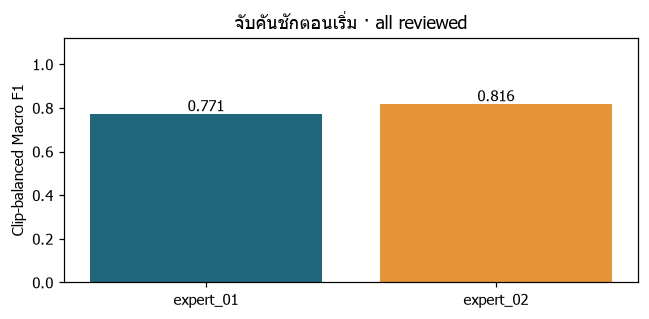

In [12]:
task = 'initial_grip'
expert_table=pd.DataFrame(results[task]['per_expert']).T
display(expert_table.round(4))
# A class can be absent for one player even when present in the full split.
expert_classes=[]
for expert,g in rows_by_task[task].groupby('expert'):
    observed=[label for label in ce.TASKS[task]['labels'] if (g.truth==label).any()]
    expert_classes.append(dict(expert=expert,
        true_class_counts=g.truth.value_counts().to_dict(),
        missing_classes=[label for label in ce.TASKS[task]['labels'] if label not in observed],
        macro_f1_observed_classes=ce.f1_score(g.truth,g.prediction,labels=observed,
            average='macro',sample_weight=ce.clip_weights(g),zero_division=0)))
display(pd.DataFrame(expert_classes).round(4))
print('The chart uses fixed classes. Missing classes can lower Macro F1 even without errors; read class counts and accuracy together.')
per_clip=pd.read_csv(REPORT/SPLIT/'selected'/f'{task}_per_clip.csv')
display(per_clip.sort_values('accuracy').head(12).round(4))
fig,ax=plt.subplots(figsize=(6,3))
bars=ax.bar(expert_table.index,expert_table.clip_balanced_macro_f1,color=['#21677c','#e59437'])
ax.bar_label(bars,fmt='%.3f'); ax.set(ylim=(0,1.12),title='จับคันชักตอนเริ่ม · all reviewed',ylabel='Clip-balanced Macro F1')
fig.tight_layout(); fig.savefig(REPORT/SPLIT/f'expert_{task}.png'); plt.show()

## 5 · รายละเอียดงาน ควรปรับองศาการสี
ตารางแรกเป็นจำนวนเฟรมจริง ส่วนตารางที่สองถ่วงน้ำหนักคลิปเท่ากัน
Confusion matrix มีคอลัมน์ “จุดไม่ครบ” เพื่อเห็นภาพที่ pipeline ประเมินไม่ได้
แถวเป็นคำตอบจริง คอลัมน์เป็นผลทำนาย

,precision,recall,f1-score,support
0,0.8125,0.6842,0.7429,76.0
1,0.9231,0.3000,0.4528,40.0
micro avg,0.8312,0.5517,0.6632,116.0
macro avg,0.8678,0.4921,0.5978,116.0
weighted avg,0.8506,0.5517,0.6428,116.0


,precision,recall,f1-score,support
0,0.9407,0.7455,0.8318,9.494
1,0.8793,0.2846,0.4300,1.506
micro avg,0.9369,0.6824,0.7897,11.000
macro avg,0.9100,0.5151,0.6309,11.000
weighted avg,0.9323,0.6824,0.7768,11.000


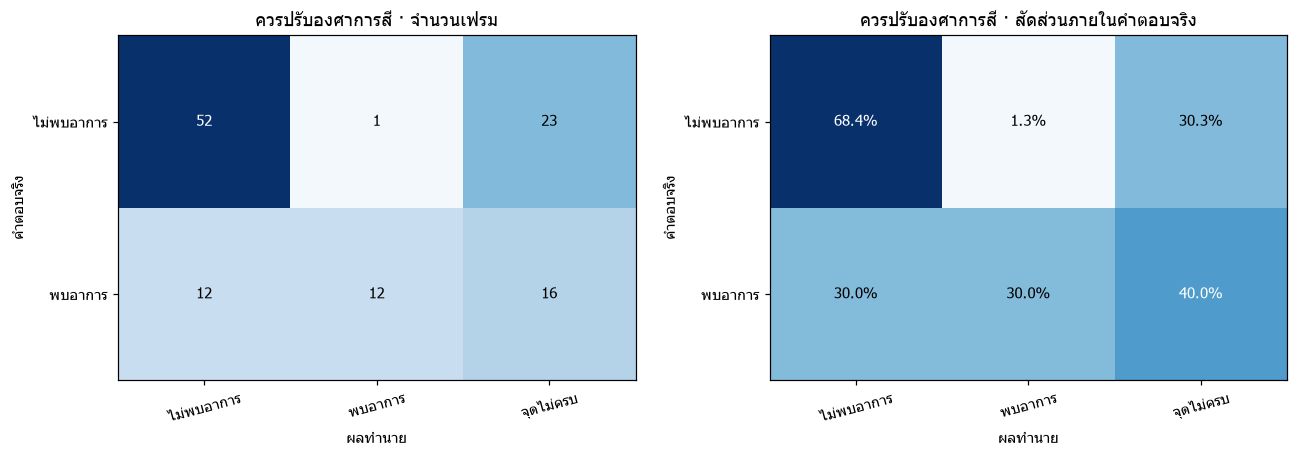

In [13]:
task = 'bow_error'
metric = results[task]
display(pd.DataFrame(metric['classification_reports']['unweighted']).T.round(4))
display(pd.DataFrame(metric['classification_reports']['clip_balanced']).T.round(4))
fig=ce.plot_confusions(task,rows_by_task[task])
fig.savefig(REPORT/SPLIT/f'confusion_{task}.png'); plt.show()

### 5 · ควรปรับองศาการสี: ผลรายคนและรายคลิป

,frames,clips,frame_accuracy,frame_macro_f1,clip_balanced_accuracy,clip_balanced_macro_f1,coverage,clip_balanced_coverage
expert_01,60.0,5.0,0.4667,0.3590,0.5952,0.3937,0.5333,0.6319
expert_02,56.0,6.0,0.6429,0.6948,0.7552,0.7414,0.8036,0.8087


,expert,true_class_counts,missing_classes,macro_f1_observed_classes
0,expert_01,"{'0': 47, '1': 13}",[],0.3937
1,expert_02,"{'0': 29, '1': 27}",[],0.7414


The chart uses fixed classes. Missing classes can lower Macro F1 even without errors; read class counts and accuracy together.


,clip_id,expert,frames,available,accuracy,positive_frames
0,expert_01/bow_hold/E01_BH_bow_angle_wrong_S01_T05.mp4.mp4,expert_01,24,8,0.2083,13
9,expert_02/playing_posture/E02_PP_head_down_S01_T04.mp4.mp4,expert_02,5,2,0.4000,0
5,expert_02/bow_hold/E02_BH_bow_angle_wrong_S01_T02.mp4.mp4,expert_02,28,22,0.4643,27
2,expert_01/playing_posture/E01_PP_correct_S01_T02.mp4.mp4,expert_01,17,10,0.5294,0
3,expert_01/playing_posture/E01_PP_head_down_S01_T03.mp4.mp4,expert_01,7,4,0.5714,0
4,expert_01/playing_posture/E01_PP_shoulder_tilt_S01_T01.mp4.mp4,expert_01,6,4,0.6667,0
10,expert_02/playing_posture/E02_PP_shoulder_tilt_S01_T05.mp4.mp4,expert_02,6,4,0.6667,0
1,expert_01/bow_hold/E01_BH_grip_too_low_S01_T03.mp4.mp4,expert_01,6,6,1.0000,0
7,expert_02/bow_hold/E02_BH_grip_too_low_S01_T05.mp4.mp4,expert_02,6,6,1.0000,0
6,expert_02/bow_hold/E02_BH_grip_too_high_S01_T05.mp4.mp4,expert_02,6,6,1.0000,0


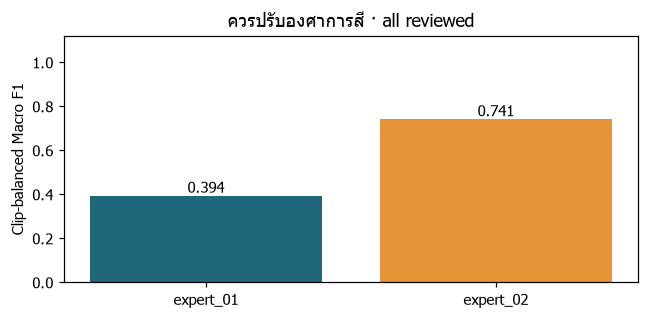

In [14]:
task = 'bow_error'
expert_table=pd.DataFrame(results[task]['per_expert']).T
display(expert_table.round(4))
# A class can be absent for one player even when present in the full split.
expert_classes=[]
for expert,g in rows_by_task[task].groupby('expert'):
    observed=[label for label in ce.TASKS[task]['labels'] if (g.truth==label).any()]
    expert_classes.append(dict(expert=expert,
        true_class_counts=g.truth.value_counts().to_dict(),
        missing_classes=[label for label in ce.TASKS[task]['labels'] if label not in observed],
        macro_f1_observed_classes=ce.f1_score(g.truth,g.prediction,labels=observed,
            average='macro',sample_weight=ce.clip_weights(g),zero_division=0)))
display(pd.DataFrame(expert_classes).round(4))
print('The chart uses fixed classes. Missing classes can lower Macro F1 even without errors; read class counts and accuracy together.')
per_clip=pd.read_csv(REPORT/SPLIT/'selected'/f'{task}_per_clip.csv')
display(per_clip.sort_values('accuracy').head(12).round(4))
fig,ax=plt.subplots(figsize=(6,3))
bars=ax.bar(expert_table.index,expert_table.clip_balanced_macro_f1,color=['#21677c','#e59437'])
ax.bar_label(bars,fmt='%.3f'); ax.set(ylim=(0,1.12),title='ควรปรับองศาการสี · all reviewed',ylabel='Clip-balanced Macro F1')
fig.tight_layout(); fig.savefig(REPORT/SPLIT/f'expert_{task}.png'); plt.show()

## 6.1 · ตรวจสองอาการพร้อมกัน
Exact match คือทายก้มหน้าและไหล่เอียงถูกทั้งคู่ในเฟรมเดียวกัน
Joint recall คือภาพที่ผิดทั้งสองอาการแล้วตรวจพบทั้งสอง; หากไม่มีภาพดังกล่าวจะไม่มีค่าคะแนนนี้
จำนวนคลิปที่มีทั้งสองอาการสำคัญกว่าจำนวนเฟรมเพียงอย่างเดียว

In [15]:
joint=ce.posture_joint(SPLIT,rows_by_task,REPORT)
display(pd.DataFrame([joint]).round(4))

,frames,exact_match,clip_balanced_exact_match,jointly_positive_frames,jointly_positive_clips,both_symptoms_detected,joint_recall
0,268,0.7164,0.6275,0,0,0,None


## 6.2 · เปิดตัวอย่างที่ทายผิดหรือประเมินไม่ได้
ตารางแสดงคำตอบจริง/ผลทำนายและตำแหน่งไฟล์ ยังคงตัวอย่างเหล่านี้ไว้ในคะแนน
ภาพตัวอย่างเป็นการทบทวนผล ไม่ใช้แก้ค่าหลังเห็น TEST ในรอบนี้

In [16]:
errors=[]
for task,rows in rows_by_task.items():
    selected=rows.loc[~rows.is_correct,['frame_path','clip_id','expert','timestamp_s','truth','prediction','geometry_status']].copy()
    selected.insert(0,'task',task)
    errors.append(selected)
error_table=pd.concat(errors,ignore_index=True)
display(error_table.groupby(['task','truth','prediction']).size().rename('frames').reset_index())
display(error_table.head(20))
error_table.to_csv(REPORT/SPLIT/'all_errors.csv',index=False,encoding='utf-8-sig')

,task,truth,prediction,frames
0,bow_error,0,1,1
1,bow_error,0,__unavailable__,23
2,bow_error,1,0,12
3,bow_error,1,__unavailable__,16
4,head_down,0,1,32
5,head_down,1,0,9
6,initial_grip,grip_too_high,none,3
7,initial_grip,grip_too_low,none,2
8,initial_grip,none,__unavailable__,17
9,initial_grip,none,grip_too_high,2


,task,frame_path,clip_id,expert,timestamp_s,truth,prediction,geometry_status
0,head_down,data/extracted/video_frames/expert_01/playing_posture/E01_PP_back_hunched_S01_T05.mp4/E01_PP_bac...,expert_01/playing_posture/E01_PP_back_hunched_S01_T05.mp4.mp4,expert_01,9.024233,0,1,ready
1,head_down,data/extracted/video_frames/expert_01/playing_posture/E01_PP_back_hunched_S01_T05.mp4/E01_PP_bac...,expert_01/playing_posture/E01_PP_back_hunched_S01_T05.mp4.mp4,expert_01,10.032267,0,1,ready
2,head_down,data/extracted/video_frames/expert_01/playing_posture/E01_PP_back_hunched_S01_T05.mp4/E01_PP_bac...,expert_01/playing_posture/E01_PP_back_hunched_S01_T05.mp4.mp4,expert_01,10.544067,0,1,ready
3,head_down,data/extracted/video_frames/expert_01/playing_posture/E01_PP_back_hunched_S01_T05.mp4/E01_PP_bac...,expert_01/playing_posture/E01_PP_back_hunched_S01_T05.mp4.mp4,expert_01,10.992033,0,1,ready
4,head_down,data/extracted/video_frames/expert_01/playing_posture/E01_PP_back_hunched_S01_T05.mp4/E01_PP_bac...,expert_01/playing_posture/E01_PP_back_hunched_S01_T05.mp4.mp4,expert_01,11.504167,0,1,ready
5,head_down,data/extracted/video_frames/expert_01/playing_posture/E01_PP_correct_S01_T02.mp4/E01_PP_correct_...,expert_01/playing_posture/E01_PP_correct_S01_T02.mp4.mp4,expert_01,43.520167,0,1,ready
6,head_down,data/extracted/video_frames/expert_01/playing_posture/E01_PP_head_down_S01_T03.mp4/E01_PP_head_d...,expert_01/playing_posture/E01_PP_head_down_S01_T03.mp4.mp4,expert_01,2.015933,1,0,ready
7,head_down,data/extracted/video_frames/expert_01/playing_posture/E01_PP_head_down_S01_T03.mp4/E01_PP_head_d...,expert_01/playing_posture/E01_PP_head_down_S01_T03.mp4.mp4,expert_01,8.527933,1,0,ready
8,head_down,data/extracted/video_frames/expert_01/playing_posture/E01_PP_head_down_S01_T03.mp4/E01_PP_head_d...,expert_01/playing_posture/E01_PP_head_down_S01_T03.mp4.mp4,expert_01,9.023967,1,0,ready
9,head_down,data/extracted/video_frames/expert_01/playing_posture/E01_PP_head_down_S01_T03.mp4/E01_PP_head_d...,expert_01/playing_posture/E01_PP_head_down_S01_T03.mp4.mp4,expert_01,9.535967,1,0,ready


**head_down** · expert_01 · 9.02s · จริง `0` / ทำนาย `1`

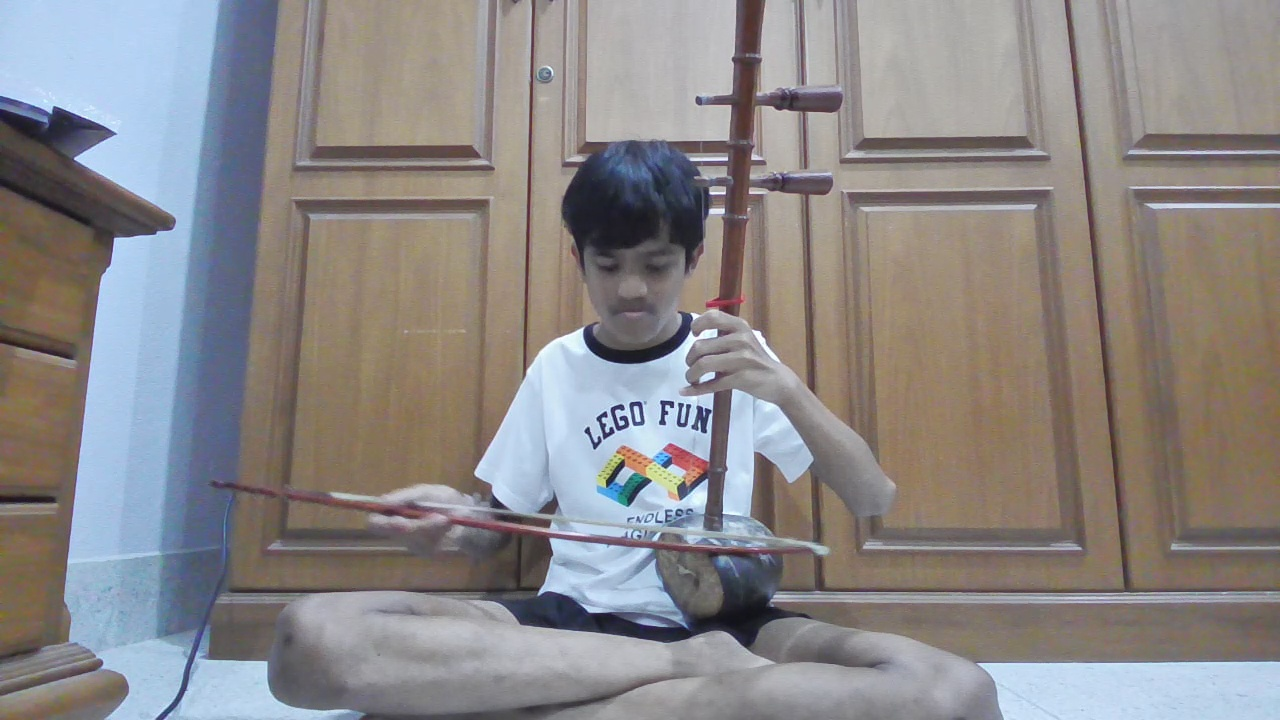

**head_down** · expert_01 · 43.52s · จริง `0` / ทำนาย `1`

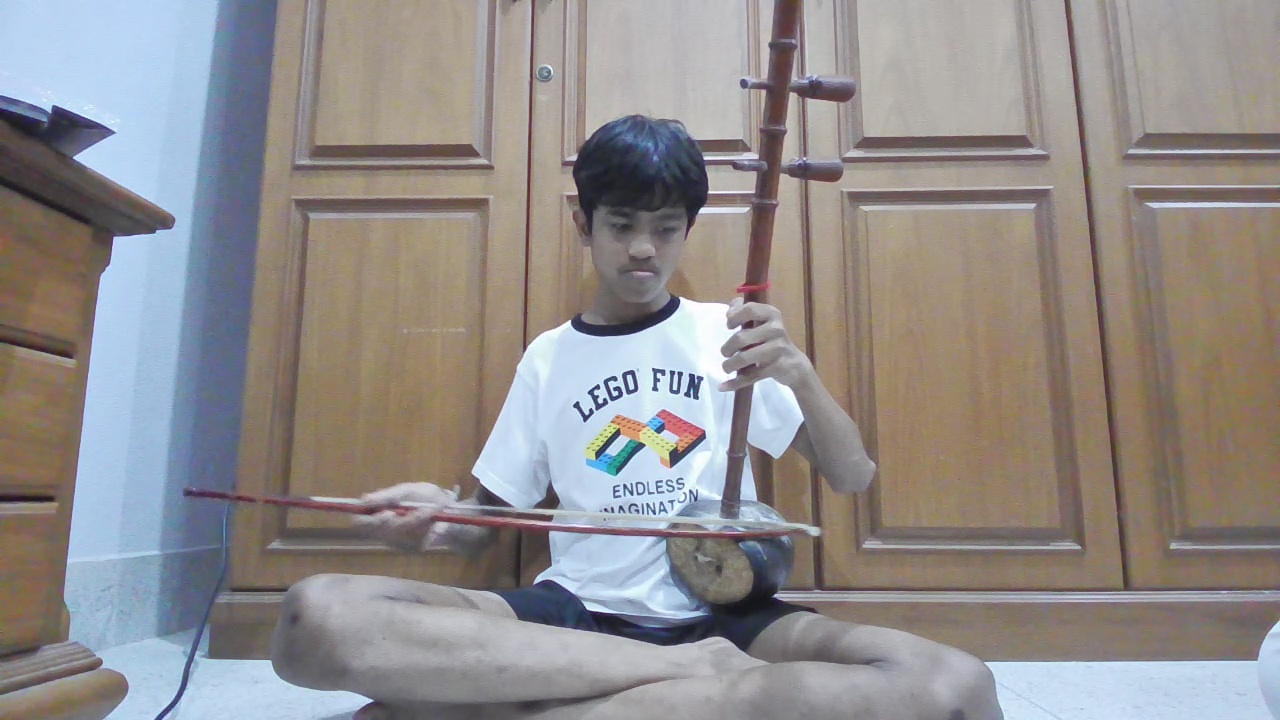

**shoulder_tilt** · expert_01 · 1.01s · จริง `0` / ทำนาย `1`

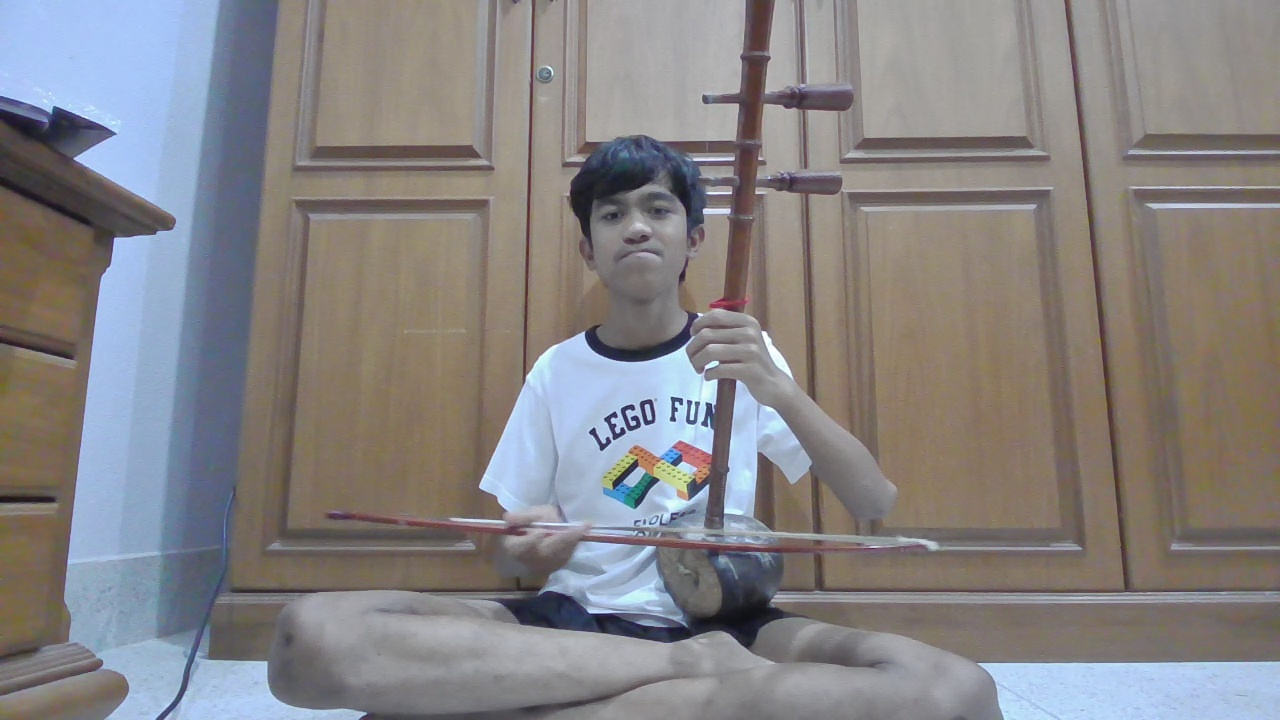

**shoulder_tilt** · expert_01 · 0.00s · จริง `0` / ทำนาย `1`

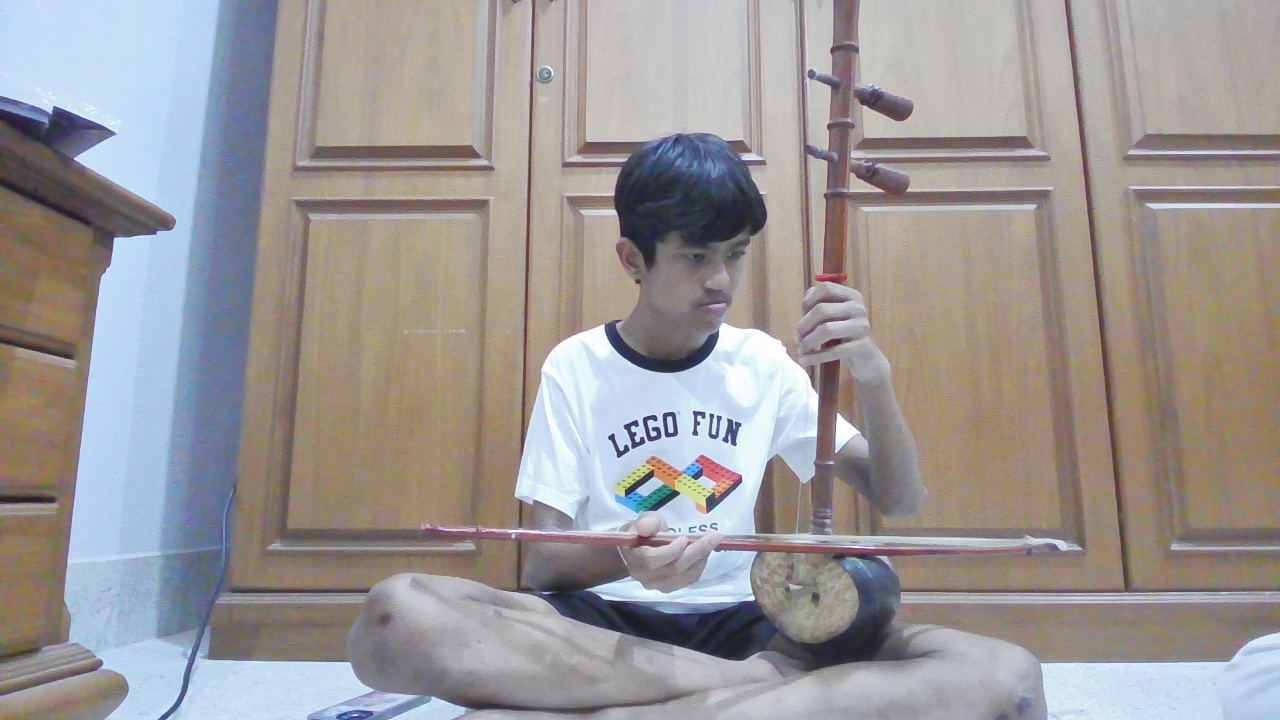

**initial_grip** · expert_01 · 5.50s · จริง `grip_too_high` / ทำนาย `none`

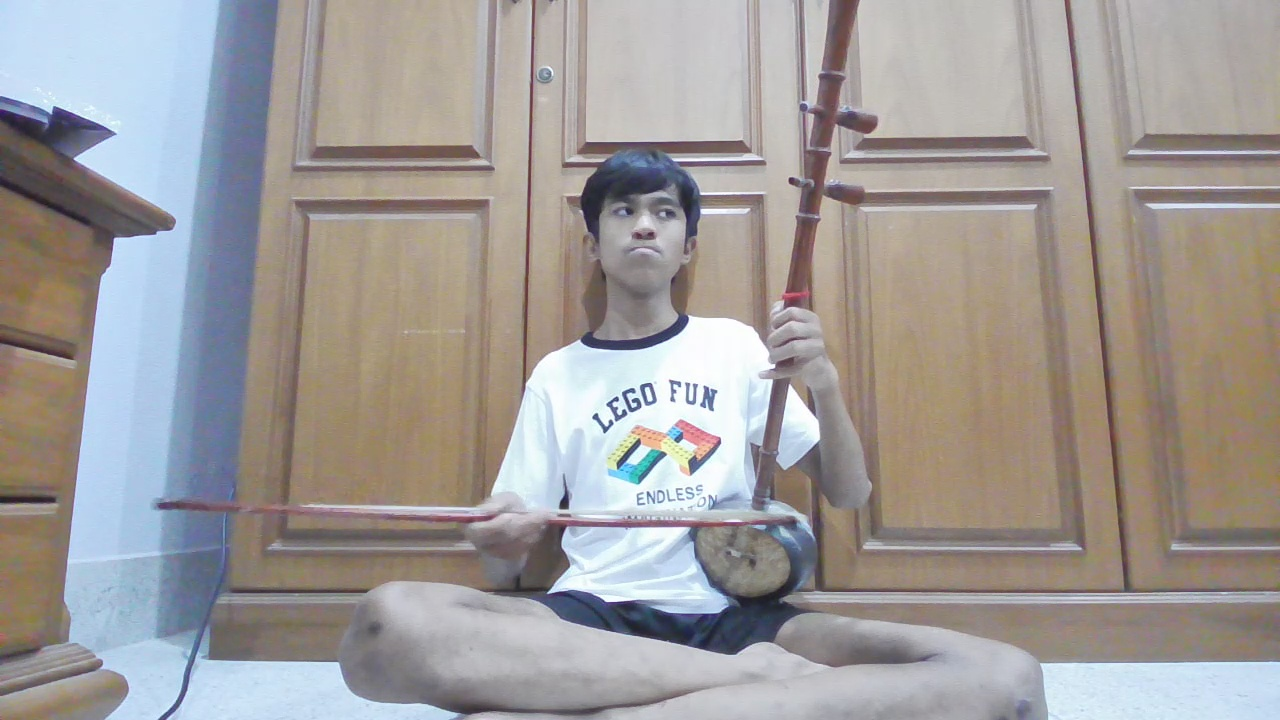

**initial_grip** · expert_01 · 6.50s · จริง `none` / ทำนาย `grip_too_high`

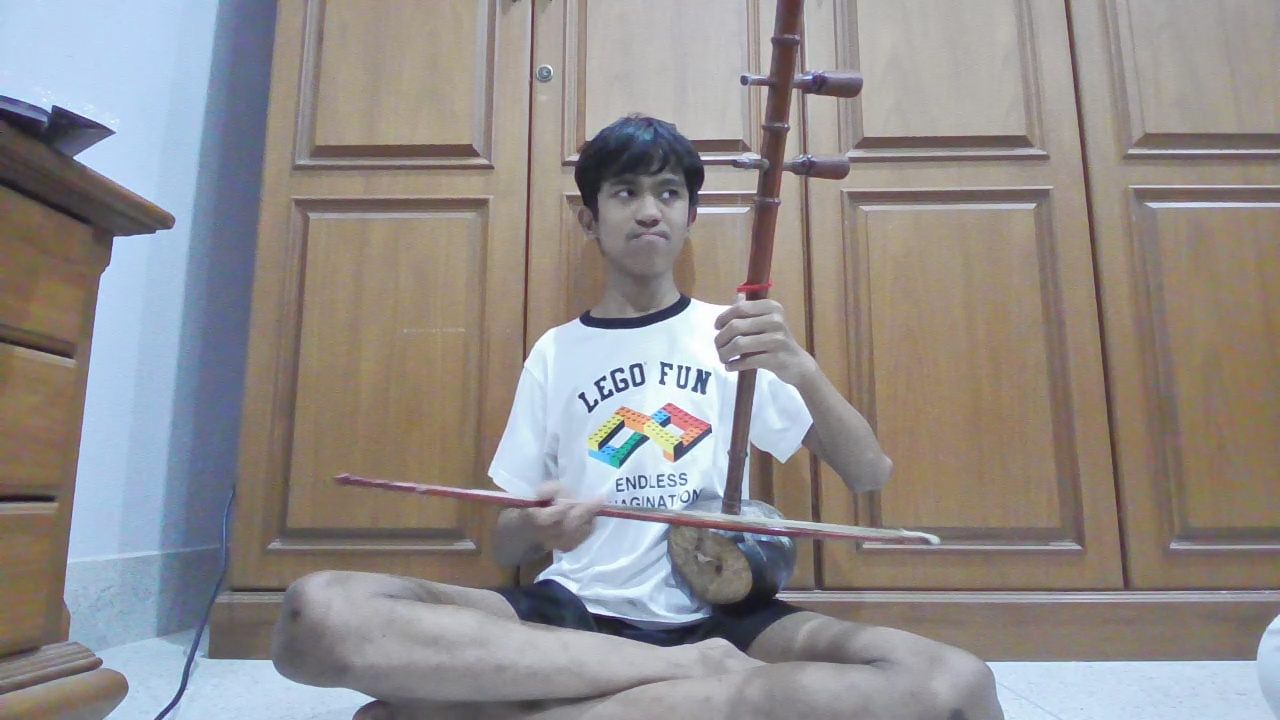

**bow_error** · expert_01 · 0.51s · จริง `0` / ทำนาย `__unavailable__`

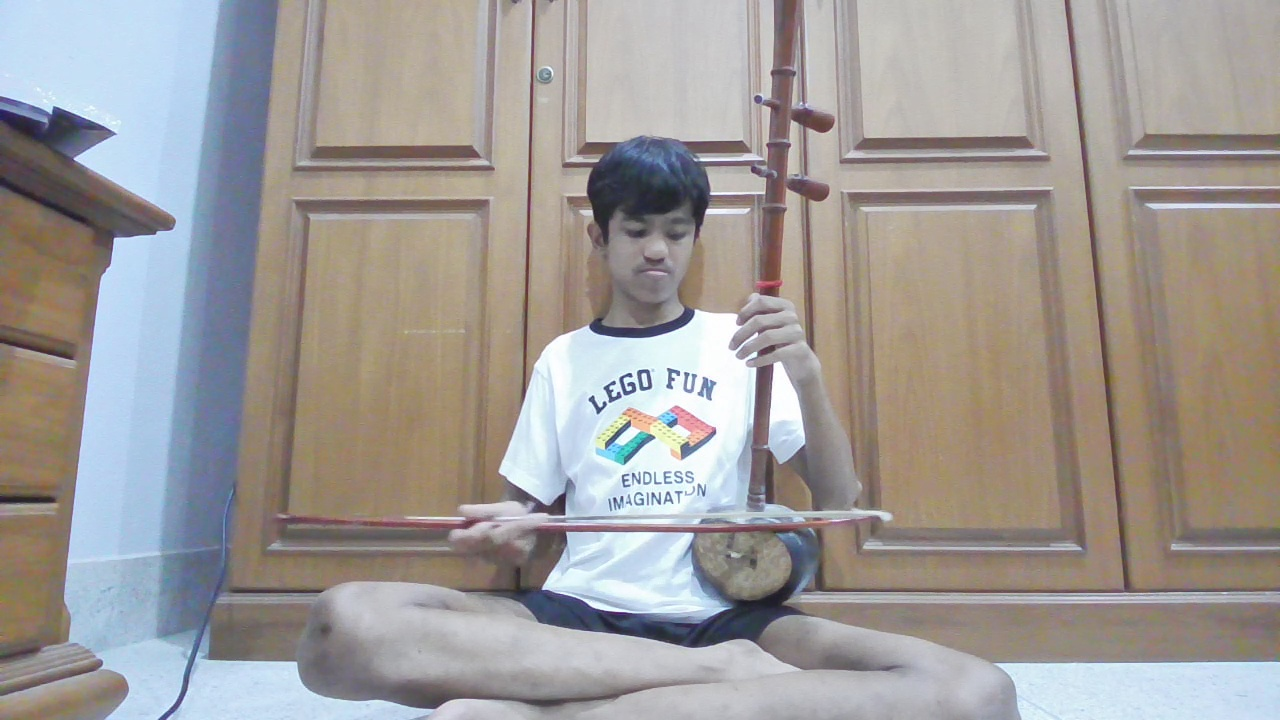

**bow_error** · expert_02 · 2.02s · จริง `1` / ทำนาย `0`

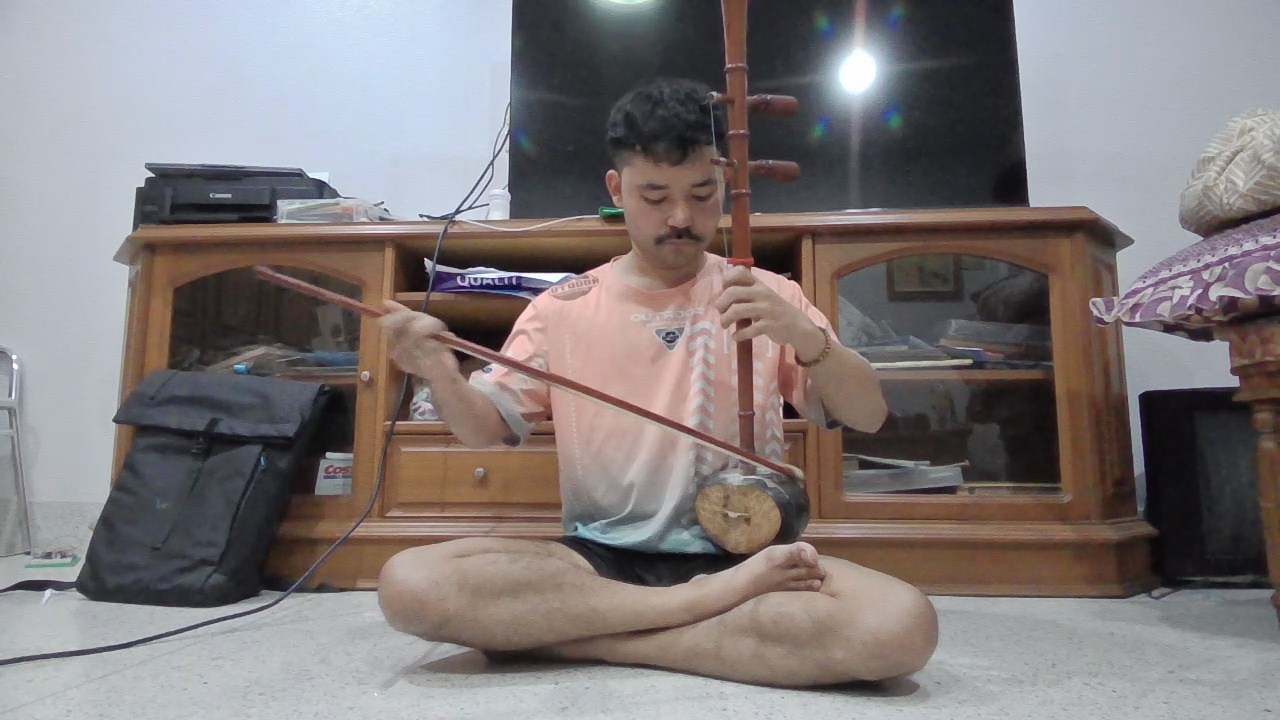

In [17]:
for task in ce.TASKS:
    examples=error_table.loc[error_table.task==task].drop_duplicates('clip_id').head(2)
    for _,row in examples.iterrows():
        display(Markdown(f"**{task}** · {row.expert} · {row.timestamp_s:.2f}s · จริง `{row.truth}` / ทำนาย `{row.prediction}`"))
        image=ce.ROOT/row.frame_path
        if image.exists(): display(Image(filename=str(image),width=440))

## 7.1 · ช่วงความไม่แน่นอนจากจำนวนคลิปน้อย
Bootstrap สุ่มซ้ำทั้งคลิป 500 ครั้ง ไม่สุ่มเฟรมแยกจากกัน
ช่วง 95% เป็นการอธิบายความแปรปรวนในชุดนี้เท่านั้น มีเพียงสองคน และบางครั้งสุ่มได้ไม่ครบคลาส
จึงไม่ใช่การรับประกันผลกับผู้เล่นใหม่

In [18]:
intervals={task:ce.bootstrap_clip_f1(rows,task,repeats=500,seed=42) for task,rows in rows_by_task.items()}
ce.save_json(REPORT/'test/bootstrap_intervals.json',intervals)
display(pd.DataFrame([dict(task=ce.TASKS[task]['title'],
    f1=results[task]['all_reviewed']['clip_balanced_macro_f1'],
    low_95=value['low'],high_95=value['high']) for task,value in intervals.items()]).round(4))

,task,f1,low_95,high_95
0,ก้มหน้า,0.6782,0.3511,0.9057
1,ไหล่เอียง,0.7830,0.4054,0.9711
2,จับคันชักตอนเริ่ม,0.8043,0.4206,0.9144
3,ควรปรับองศาการสี,0.6309,0.3833,0.7501


## 7.2 · อ่านผล VAL และ TEST ให้ถูกต้อง
VAL ใช้โมเดล fit TRAIN; TEST ใช้โมเดล fit TRAIN+VAL จึงไม่ได้เป็นการประเมิน estimator ตัวเดียวกัน
ตารางนี้ช่วยดูความต่างของชุดข้อมูล แต่ห้ามตีความว่า TEST สูงกว่าแปลว่าโมเดลดีขึ้นจากการปรับค่า

,task,val_f1,test_f1,val_coverage,test_coverage
0,ก้มหน้า,0.7072,0.6782,1.0000,1.0000
1,ไหล่เอียง,0.7494,0.7830,1.0000,1.0000
2,จับคันชักตอนเริ่ม,0.7486,0.8043,0.7985,0.7893
3,ควรปรับองศาการสี,0.7190,0.6309,0.7606,0.7284


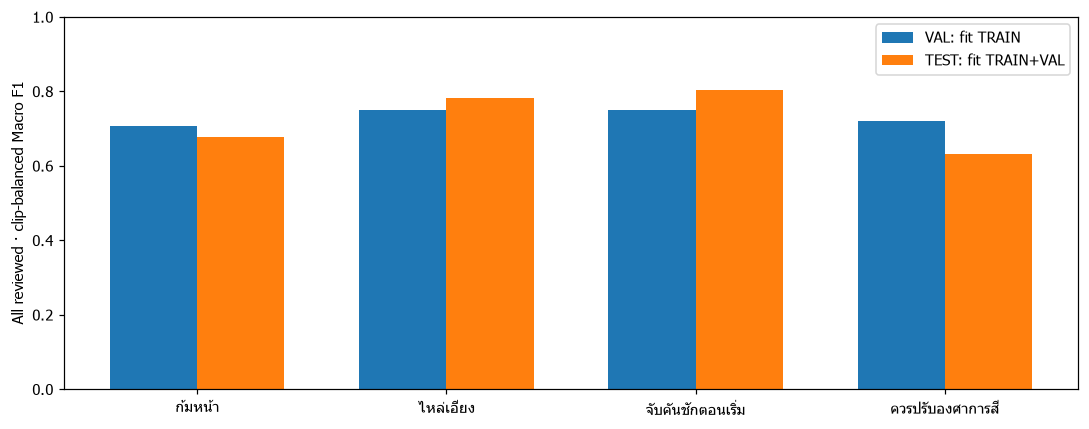

In [19]:
validation=ce.read_json(REPORT/'val/results.json')
comparison=pd.DataFrame([dict(task=ce.TASKS[task]['title'],
    val_f1=validation[task]['all_reviewed']['clip_balanced_macro_f1'],
    test_f1=results[task]['all_reviewed']['clip_balanced_macro_f1'],
    val_coverage=validation[task]['all_reviewed']['clip_balanced_coverage'],
    test_coverage=results[task]['all_reviewed']['clip_balanced_coverage']) for task in ce.TASKS])
display(comparison.round(4))
fig,ax=plt.subplots(figsize=(10,4)); x=np.arange(len(comparison)); width=.35
ax.bar(x-width/2,comparison.val_f1,width,label='VAL: fit TRAIN')
ax.bar(x+width/2,comparison.test_f1,width,label='TEST: fit TRAIN+VAL')
ax.set_xticks(x,comparison.task); ax.set(ylim=(0,1),ylabel='All reviewed · clip-balanced Macro F1'); ax.legend()
fig.tight_layout(); fig.savefig(REPORT/'test/val_test_comparison.png'); plt.show()

## 8.1 · สรุปผลและข้อจำกัด
อ่านทั้ง F1/Recall รายคลาส ผลรายคน Coverage และตัวอย่างผิดควบคู่กัน
การตรวจคันชักเป็นการทดลองจากร่างกาย; ยังไม่มีข้อมูลผู้เล่นคนที่สามหรือกล้อง/สถานที่ใหม่ที่กันไว้ทั้งคน
ไม่มีการนำรุ่นนี้ไปใช้เว็บอัตโนมัติ และคะแนนนี้ยังไม่รวม temporal smoothing/uncertainty guard ของเว็บ

In [20]:
lines=[]
for task,r in results.items():
    m=r['all_reviewed']; u=r['conditional']
    lines.append(f"- **{ce.TASKS[task]['title']}**: {r['family']}, F1 แบบคลิปเท่ากันเมื่อจุดครบ **{u['clip_balanced_macro_f1']:.3f}**, รวมจุดไม่ครบ **{m['clip_balanced_macro_f1']:.3f}**, coverage **{m['clip_balanced_coverage']:.1%}**, {m['frames']} เฟรม / {m['clips']} คลิป")
display(Markdown('\n'.join(lines)))
assert WEB_BEFORE == ce.web_fingerprints(), 'Web model changed during this run'
print('Web model unchanged: verified')
print('Report directory:',REPORT/SPLIT)

- **ก้มหน้า**: random_forest, F1 แบบคลิปเท่ากันเมื่อจุดครบ **0.678**, รวมจุดไม่ครบ **0.678**, coverage **100.0%**, 268 เฟรม / 7 คลิป
- **ไหล่เอียง**: random_forest, F1 แบบคลิปเท่ากันเมื่อจุดครบ **0.783**, รวมจุดไม่ครบ **0.783**, coverage **100.0%**, 268 เฟรม / 7 คลิป
- **จับคันชักตอนเริ่ม**: random_forest, F1 แบบคลิปเท่ากันเมื่อจุดครบ **0.865**, รวมจุดไม่ครบ **0.804**, coverage **78.9%**, 70 เฟรม / 10 คลิป
- **ควรปรับองศาการสี**: decision_tree, F1 แบบคลิปเท่ากันเมื่อจุดครบ **0.754**, รวมจุดไม่ครบ **0.631**, coverage **72.8%**, 116 เฟรม / 11 คลิป

Web model unchanged: verified
Report directory: E:\Kamsuay\SawUAI\training\reports\combined_experts_20261007_211339_512861\test


## วิเคราะห์ผล Test จากคำตอบจริง

ผลนี้ใช้รายงานหลังล็อกตัวเลือก ไม่มีการปรับพารามิเตอร์จาก TEST ทั้งสองคนมีตัวอย่างในชุดฝึก จึงไม่ใช่ผลทดสอบผู้เล่นใหม่ทั้งคน

### ก้มหน้า

TEST usable 268 / reviewed 268 เฟรม จาก 7 คลิป; Accuracy เมื่อจุดครบ **84.7%**, F1 แบบคลิปเท่ากันเมื่อจุดครบ **0.678**, รวมจุดไม่ครบ **0.678**

Coverage แบบรายเฟรม **100.0%** และแบบคลิปเท่ากัน **100.0%**

- พบอาการ: Precision **40.7%**, Recall **71.0%**, F1 **0.518**, คำตอบจริง 31 เฟรม (รวม landmark ไม่ครบ)

- expert_01: คำตอบจริง `{'0': 154, '1': 30}`, accuracy แบบคลิปเท่ากัน **88.7%**, F1 ทุกคลาส **0.840**

- expert_02: คำตอบจริง `{'0': 83, '1': 1}`, accuracy แบบคลิปเท่ากัน **66.7%**, F1 ทุกคลาส **0.400**

ข้อผิดพลาดหลัก: จริง `0` → ทำนาย `1` 32 เฟรม; จริง `1` → ทำนาย `0` 9 เฟรม

### ไหล่เอียง

TEST usable 268 / reviewed 268 เฟรม จาก 7 คลิป; Accuracy เมื่อจุดครบ **84.0%**, F1 แบบคลิปเท่ากันเมื่อจุดครบ **0.783**, รวมจุดไม่ครบ **0.783**

Coverage แบบรายเฟรม **100.0%** และแบบคลิปเท่ากัน **100.0%**

- พบอาการ: Precision **55.7%**, Recall **92.5%**, F1 **0.695**, คำตอบจริง 53 เฟรม (รวม landmark ไม่ครบ)

- expert_01: คำตอบจริง `{'0': 159, '1': 25}`, accuracy แบบคลิปเท่ากัน **70.0%**, F1 ทุกคลาส **0.675**

- expert_02: คำตอบจริง `{'0': 56, '1': 28}`, accuracy แบบคลิปเท่ากัน **93.1%**, F1 ทุกคลาส **0.926**

ข้อผิดพลาดหลัก: จริง `0` → ทำนาย `1` 39 เฟรม; จริง `1` → ทำนาย `0` 4 เฟรม

### จับคันชักตอนเริ่ม

TEST usable 53 / reviewed 70 เฟรม จาก 10 คลิป; Accuracy เมื่อจุดครบ **86.8%**, F1 แบบคลิปเท่ากันเมื่อจุดครบ **0.865**, รวมจุดไม่ครบ **0.804**

Coverage แบบรายเฟรม **75.7%** และแบบคลิปเท่ากัน **78.9%**

- จับพอดี: Precision **84.4%**, Recall **58.7%**, F1 **0.692**, คำตอบจริง 46 เฟรม (รวม landmark ไม่ครบ)

- จับสูง: Precision **81.8%**, Recall **75.0%**, F1 **0.783**, คำตอบจริง 12 เฟรม (รวม landmark ไม่ครบ)

- จับต่ำ: Precision **100.0%**, Recall **83.3%**, F1 **0.909**, คำตอบจริง 12 เฟรม (รวม landmark ไม่ครบ)

- expert_01: คำตอบจริง `{'none': 30, 'grip_too_high': 6, 'grip_too_low': 6}`, accuracy แบบคลิปเท่ากัน **65.4%**, F1 ทุกคลาส **0.771**

- expert_02: คำตอบจริง `{'none': 16, 'grip_too_high': 6, 'grip_too_low': 6}`, accuracy แบบคลิปเท่ากัน **71.3%**, F1 ทุกคลาส **0.816**

ข้อผิดพลาดหลัก: จริง `none` → ทำนาย `__unavailable__` 17 เฟรม; จริง `grip_too_high` → ทำนาย `none` 3 เฟรม; จริง `grip_too_low` → ทำนาย `none` 2 เฟรม

### ควรปรับองศาการสี

TEST usable 77 / reviewed 116 เฟรม จาก 11 คลิป; Accuracy เมื่อจุดครบ **83.1%**, F1 แบบคลิปเท่ากันเมื่อจุดครบ **0.754**, รวมจุดไม่ครบ **0.631**

Coverage แบบรายเฟรม **66.4%** และแบบคลิปเท่ากัน **72.8%**

- พบอาการ: Precision **92.3%**, Recall **30.0%**, F1 **0.453**, คำตอบจริง 40 เฟรม (รวม landmark ไม่ครบ)

- expert_01: คำตอบจริง `{'0': 47, '1': 13}`, accuracy แบบคลิปเท่ากัน **59.5%**, F1 ทุกคลาส **0.394**

- expert_02: คำตอบจริง `{'0': 29, '1': 27}`, accuracy แบบคลิปเท่ากัน **75.5%**, F1 ทุกคลาส **0.741**

ข้อผิดพลาดหลัก: จริง `0` → ทำนาย `__unavailable__` 23 เฟรม; จริง `1` → ทำนาย `__unavailable__` 16 เฟรม; จริง `1` → ทำนาย `0` 12 เฟรม

### ข้อสรุปที่ใช้ตัดสินใจก่อนนำไปเว็บ

ท่านั่งทายถูกทั้งสองคำตอบต่อเฟรม **71.6%** หรือ **62.7%** เมื่อคลิปมีน้ำหนักเท่ากัน

TEST ไม่มีเฟรมที่ก้มหน้าและไหล่เอียงพร้อมกัน จึงยังวัด Recall ของกรณีผิดทั้งคู่ไม่ได้ แม้โครงสร้างโมเดลให้สองคำตอบเป็น 1 พร้อมกันได้

การจับสูง–ต่ำให้ผลดีกว่าเมื่อ feature ครบ แต่ต้องอ่าน coverage ประกอบ คำเตือนปรับองศาการสียังมี Recall ของภาพผิดต่ำ จึงควรถือเป็นรุ่นทดลองและแจ้งข้อจำกัดก่อนใช้งาน

คะแนน usable และ all-reviewed มีน้ำหนักต่อเฟรมต่างกันตามจำนวนเฟรมต่อคลิป เมื่อรวม landmark ที่ขาด Macro F1 อาจเพิ่มหรือลดได้จากการเปลี่ยนสัดส่วนคลาส จึงต้องอ่าน Accuracy, Recall และ Coverage ด้วย

ช่วง clip bootstrap ในตารางด้านบนกว้าง เพราะคลิปและผู้เล่นมีน้อย ควรเก็บคน/กล้อง/สถานที่ใหม่เป็นชุดยืนยัน ไม่ใช้ TEST เดิมไล่ปรับพารามิเตอร์

**โมเดลเว็บไซต์ยังเป็นรุ่นเดิม รอผู้ใช้ตัดสินใจก่อนนำรุ่นนี้ไปใช้**